Mounted at /content/drive
Google Drive project paths: VERIFIED
Research provenance: PASS
Training images: 33
Reserved evaluation images: 60
Train/evaluation filename overlap: ZERO
Original architecture: LOADED
Target normalization: 54.5197
Original input tensors: (33, 5, 160, 160)
Original target tensors: (33, 1, 160, 160)
Mask-only input preparation: PASS
RGB features: DISABLED
Segmentation masks: PRESERVED
Confidence channel: FIXED AT 1.0

Original RGB experiment reproduced: PASS
RGB model TRAIN-ONLY MAE: 0.23727
Zero baseline TRAIN-ONLY MAE: 0.58354

Starting matched mask-only training...
Device: cpu
Epoch 01/12 | MASK-ONLY TRAIN MAE: 0.32315
Epoch 02/12 | MASK-ONLY TRAIN MAE: 0.24057
Epoch 03/12 | MASK-ONLY TRAIN MAE: 0.23405
Epoch 04/12 | MASK-ONLY TRAIN MAE: 0.22963
Epoch 05/12 | MASK-ONLY TRAIN MAE: 0.29482
Epoch 06/12 | MASK-ONLY TRAIN MAE: 0.25536
Epoch 07/12 | MASK-ONLY TRAIN MAE: 0.24132
Epoch 08/12 | MASK-ONLY TRAIN MAE: 0.23652
Epoch 09/12 | MASK-ONLY TRAIN MAE: 0.25278
Ep

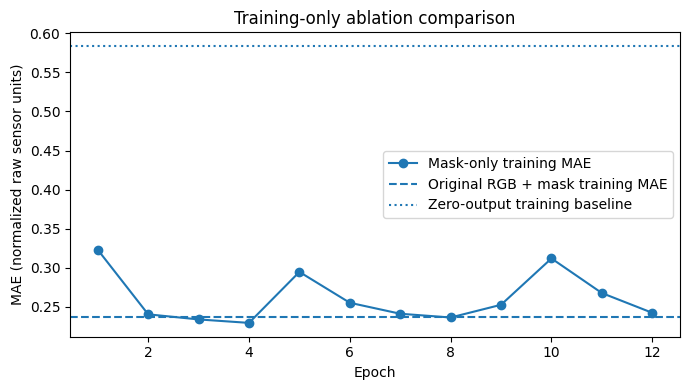


C3-03 SECTION 4A — MASK-ONLY TRAINING COMPLETE
Training images: 33
Original RGB TRAIN-ONLY MAE: 0.23727
Mask-only TRAIN-ONLY MAE: 0.22963
Mask-only best epoch: 4
Saved checkpoint reload: PASS
Standalone inference: PASS
Section 3 evaluation reused for training: NO
Held-out ablation evaluation completed: NO
Metric depth accuracy: NOT VERIFIED
Physical severity: NOT AUTHORIZED

Training output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-03_section04_MASK_ONLY_ABLATION_20261020T101207_202510Z
Checkpoint output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-03_section04_MASK_ONLY_ABLATION_20261020T101207_202510Z


In [ ]:

# ============================================================
# CRDL C3-03 SECTION 4A — MASK-ONLY MODEL ABLATION
#
# SELF-CONTAINED COLAB CELL
# No downloaded script / no file upload required
#
# Trains a mask-only model using the same 33 examples,
# architecture, loss and training schedule as Section 2.
#
# Nonmetric engineering experiment only.
# No physical-depth or independent-validation claims.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image
import csv
import json
import hashlib
import shutil
import sys
import random
import importlib.util

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. GOOGLE DRIVE AND EXISTING PROJECT PATHS
# ------------------------------------------------------------

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

S14 = BASE / (
    "04_geometry_targets/"
    "C3-02_section14_PothRGBD_PILOT_20261020T081321_368363Z"
)

S16 = BASE / (
    "04_geometry_targets/"
    "C3-02_section16_AFFINE_EXPANSION_20261020T082927_408953Z"
)

SECTION2_NAME = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)

OLD_RUN = (
    BASE / "05_training_runs" / SECTION2_NAME
)

OLD_CKPT = (
    BASE / "06_model_checkpoints" / SECTION2_NAME
)

S3 = BASE / (
    "07_evaluation/"
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)

for folder in (
    S14,
    S16,
    OLD_RUN,
    OLD_CKPT,
    S3,
    DATA / "images"
):
    assert folder.is_dir(), (
        f"Missing project folder: {folder}"
    )

print("Google Drive project paths: VERIFIED")


# ------------------------------------------------------------
# 2. VERIFY EXISTING RESEARCH FILES
# ------------------------------------------------------------

def sha256(path):

    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def verify_checksums(folder, required):

    expected = {}

    path = folder / "checksums.sha256"

    assert path.is_file(), path

    for line in path.read_text().splitlines():

        if not line.strip():
            continue

        digest, relative = line.split(None, 1)
        relative = relative.strip()

        rel = Path(relative)

        assert not rel.is_absolute()
        assert ".." not in rel.parts
        assert relative not in expected

        expected[relative] = digest

    for name in required:

        assert name in expected, (
            f"Missing checksum for {name}"
        )

        assert sha256(folder / name) == expected[name], (
            f"Checksum mismatch: {folder / name}"
        )

    return expected


h14 = verify_checksums(
    S14, ["pilot_quality_report.json"]
)

h16 = verify_checksums(
    S16, ["expansion_quality_report.json"]
)

h2run = verify_checksums(
    OLD_RUN,
    [
        "training_config.json",
        "train_only_manifest.csv"
    ]
)

h2ckpt = verify_checksums(
    OLD_CKPT,
    [
        "model_development_only.pt",
        "crdl_dev_model.py",
        "crdl_dev_infer.py",
        "api_contract.json"
    ]
)

h3 = verify_checksums(
    S3,
    [
        "frozen_unseen_probe_report.json",
        "selected_unseen_samples.csv"
    ]
)

p14 = json.loads(
    (S14 / "pilot_quality_report.json").read_text()
)

p16 = json.loads(
    (S16 / "expansion_quality_report.json").read_text()
)

old_config = json.loads(
    (OLD_RUN / "training_config.json").read_text()
)

s3_report = json.loads(
    (S3 / "frozen_unseen_probe_report.json").read_text()
)

assert p14["configuration"] == p16["config"]

assert old_config["source_count"] == 33
assert old_config["epochs"] == 12

assert old_config["validation_performed"] is False

assert s3_report["summary"]["attempted"] == 60
assert (
    s3_report["summary"]["accepted_evaluation_count"]
    == 13
)

assert (
    s3_report["checkpoint_sha256"]
    == h2ckpt["model_development_only.pt"]
)

with (
    OLD_RUN / "train_only_manifest.csv"
).open(newline="") as f:

    manifest = list(csv.DictReader(f))

assert len(manifest) == 33

train_ids = {
    row["sample_id"]
    for row in manifest
}

assert len(train_ids) == 33

approved_ids = {
    row["sample_id"]
    for row in (
        p14["records"] + p16["records"]
    )
    if row["status"] == "DIAGNOSTIC_PASS"
}

assert train_ids == approved_ids

reserved_ids = {
    row["sample_id"]
    for row in s3_report["records"]
}

assert len(reserved_ids) == 60
assert train_ids.isdisjoint(reserved_ids)

print("Research provenance: PASS")
print("Training images:", len(train_ids))
print("Reserved evaluation images:", len(reserved_ids))
print("Train/evaluation filename overlap: ZERO")


# ------------------------------------------------------------
# 3. LOAD ORIGINAL NETWORK ARCHITECTURE
# DIRECTLY FROM THE EXISTING DRIVE CHECKPOINT
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "crdl_section04_original_arch",
    OLD_CKPT / "crdl_dev_model.py"
)

arch = importlib.util.module_from_spec(spec)
spec.loader.exec_module(arch)

CRDLDevUNet = arch.CRDLDevUNet
encode_input = arch.encode_input

original = torch.load(
    OLD_CKPT / "model_development_only.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    original["contract_version"]
    == "C3_DEV_NONMETRIC_V1"
)

assert original["metric_units_verified"] is False

SCALE = float(original["raw_target_scale"])

assert np.isclose(
    SCALE,
    old_config["raw_target_normalizer"],
    atol=1e-6
)

print("Original architecture: LOADED")
print("Target normalization:", round(SCALE, 4))


# ------------------------------------------------------------
# 4. RECONSTRUCT THE EXACT 33 TRAINING TENSORS
# ------------------------------------------------------------

X = []
Y = []
W = []

for row in manifest:

    stage_name = row["source_stage"]

    assert stage_name in {
        S14.name,
        S16.name
    }

    if stage_name == S14.name:
        source_folder = S14
        hashes = h14
    else:
        source_folder = S16
        hashes = h16

    relative = row["npz_relative"]

    assert relative.startswith(
        "diagnostic_pass_npz/"
    )

    assert relative in hashes

    target_file = source_folder / relative

    rgb_file = (
        DATA / "images" / row["rgb_filename"]
    )

    assert target_file.is_file()
    assert rgb_file.is_file()

    assert (
        sha256(target_file)
        == hashes[relative]
        == row["npz_sha256"]
    )

    assert (
        sha256(rgb_file)
        == row["rgb_sha256"]
    )

    with Image.open(rgb_file) as im:

        # A writable copy prevents the earlier
        # NumPy / PyTorch read-only array warning.
        rgb = np.array(
            im.convert("RGB"),
            copy=True
        )

    with np.load(
        target_file,
        allow_pickle=False
    ) as z:

        target_raw = z[
            "signed_axial_raw"
        ].astype(np.float32)

        damage_mask = z[
            "damage_mask"
        ].astype(bool)

        valid_mask = z[
            "valid_target_mask"
        ].astype(bool)

    assert (
        target_raw.shape
        == damage_mask.shape
        == valid_mask.shape
        == rgb.shape[:2]
    )

    assert np.array_equal(
        np.isfinite(target_raw),
        valid_mask
    )

    assert np.all(
        ~valid_mask | damage_mask
    )

    x, geom = encode_input(
        rgb,
        damage_mask,
        confidence=1.0,
        size=160
    )

    nh, nw = geom["resized_hw"]

    top = geom["pad_top"]
    left = geom["pad_left"]

    # Same validity-aware resizing
    # as the original Section 2 model.

    valid_small = F.interpolate(
        torch.from_numpy(
            valid_mask.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid_mask,
                target_raw,
                0.0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    resized_mask = x[
        3,
        top:top + nh,
        left:left + nw
    ][None, None]

    weight = (
        (valid_small >= 0.90).float()
        * resized_mask
    )

    y = torch.where(
        weight > 0,
        (
            numerator
            / valid_small.clamp_min(1e-8)
        ) / SCALE,
        torch.zeros_like(numerator)
    )

    padding = (
        left,
        160 - nw - left,
        top,
        160 - nh - top
    )

    y = F.pad(
        y,
        padding
    ).squeeze(0)

    weight = F.pad(
        weight,
        padding
    ).squeeze(0)

    assert float(weight.sum()) > 5
    assert torch.isfinite(y).all()

    X.append(x)
    Y.append(y)
    W.append(weight)


X = torch.stack(X)
Y = torch.stack(Y)
W = torch.stack(W)

assert X.shape == (33, 5, 160, 160)
assert Y.shape == (33, 1, 160, 160)
assert W.shape == (33, 1, 160, 160)

print("Original input tensors:", tuple(X.shape))
print("Original target tensors:", tuple(Y.shape))


# ------------------------------------------------------------
# 5. CREATE MASK-ONLY INPUTS
# ------------------------------------------------------------

X_MASK = X.clone()

# RGB information is removed.
X_MASK[:, 0:3, :, :] = 0.0

# Pothole mask and confidence are unchanged.
assert torch.count_nonzero(
    X_MASK[:, 0:3]
) == 0

assert torch.equal(
    X_MASK[:, 3:],
    X[:, 3:]
)

print("Mask-only input preparation: PASS")
print("RGB features: DISABLED")
print("Segmentation masks: PRESERVED")
print("Confidence channel: FIXED AT 1.0")


# ------------------------------------------------------------
# 6. REPRODUCE ORIGINAL RGB MODEL TRAINING ERROR
# ------------------------------------------------------------

rgb_model = CRDLDevUNet()

rgb_model.load_state_dict(
    original["state_dict"],
    strict=True
)

rgb_model.eval()

with torch.no_grad():

    error_sum = 0.0

    for ids in torch.arange(33).split(4):

        pred = rgb_model(X[ids])

        error_sum += float(
            (
                (pred - Y[ids]).abs()
                * W[ids]
            ).sum()
        )

    rgb_train_mae = (
        error_sum / float(W.sum())
    )

zero_baseline = float(
    (Y.abs() * W).sum() / W.sum()
)

assert abs(
    rgb_train_mae
    - old_config["best_train_mae_norm"]
) < 1e-4

assert abs(
    zero_baseline
    - old_config["baseline_zero_train_mae_norm"]
) < 1e-4

print("\nOriginal RGB experiment reproduced: PASS")
print(
    "RGB model TRAIN-ONLY MAE:",
    round(rgb_train_mae, 5)
)
print(
    "Zero baseline TRAIN-ONLY MAE:",
    round(zero_baseline, 5)
)


# ------------------------------------------------------------
# 7. CREATE NEW VERSIONED OUTPUT FOLDERS
# ------------------------------------------------------------

timestamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

name = (
    "C3-03_section04_MASK_ONLY_ABLATION_"
    + timestamp
)

RUN = (
    BASE / "05_training_runs" / name
)

CKPT = (
    BASE / "06_model_checkpoints" / name
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

CKPT.mkdir(
    parents=True,
    exist_ok=False
)

# Copy original architecture to the new
# checkpoint for reproducible inference.
shutil.copy2(
    OLD_CKPT / "crdl_dev_model.py",
    CKPT / "crdl_dev_model.py"
)


# ------------------------------------------------------------
# 8. MATCHED MASK-ONLY NETWORK TRAINING
# ------------------------------------------------------------

SEED = 20261020
EPOCHS = 12
BATCH_SIZE = 4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.set_num_threads(
        min(4, torch.get_num_threads())
    )
except RuntimeError:
    pass

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

mask_model = CRDLDevUNet().to(device)

optimizer = torch.optim.AdamW(
    mask_model.parameters(),
    lr=7e-4,
    weight_decay=1e-4
)

history = []

best_mae = float("inf")
best_epoch = None

print("\nStarting matched mask-only training...")
print("Device:", device)

for epoch in range(1, EPOCHS + 1):

    mask_model.train()

    order = torch.randperm(
        len(X_MASK),
        generator=(
            torch.Generator().manual_seed(
                SEED + epoch
            )
        )
    )

    train_loss_sum = 0.0
    train_weight_sum = 0.0

    for ids in order.split(BATCH_SIZE):

        xb = X_MASK[ids].to(device)
        yb = Y[ids].to(device)
        wb = W[ids].to(device)

        optimizer.zero_grad(
            set_to_none=True
        )

        predictions = mask_model(xb)

        loss = (
            F.smooth_l1_loss(
                predictions,
                yb,
                reduction="none",
                beta=0.2
            ) * wb
        ).sum() / wb.sum().clamp_min(1)

        if not torch.isfinite(loss):
            raise RuntimeError(
                "Nonfinite training loss"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            mask_model.parameters(),
            1.0
        )

        optimizer.step()

        batch_weight = float(
            wb.sum()
        )

        train_loss_sum += (
            float(loss.detach())
            * batch_weight
        )

        train_weight_sum += batch_weight

    # TRAINING-ONLY assessment.
    # No reserved evaluation frame is accessed.

    mask_model.eval()

    with torch.no_grad():

        absolute_error = 0.0

        for ids in torch.arange(
            len(X_MASK)
        ).split(BATCH_SIZE):

            prediction = mask_model(
                X_MASK[ids].to(device)
            ).cpu()

            absolute_error += float(
                (
                    (prediction - Y[ids]).abs()
                    * W[ids]
                ).sum()
            )

    mae = (
        absolute_error
        / float(W.sum())
    )

    history.append({
        "epoch": epoch,
        "train_smoothl1": (
            train_loss_sum
            / max(train_weight_sum, 1.0)
        ),
        "train_masked_mae_norm": mae
    })

    if mae < best_mae:

        best_mae = mae
        best_epoch = epoch

        torch.save(
            {
                "state_dict": (
                    mask_model.state_dict()
                ),
                "contract_version": (
                    "C3_MASK_ONLY_ABLATION_V1"
                ),
                "raw_target_scale": SCALE,
                "training_only": True,
                "rgb_channels_disabled": True,
                "confidence_training_value": 1.0,
                "best_training_epoch": epoch,
                "metric_units_verified": False
            },
            CKPT / "mask_only_ablation.pt"
        )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"MASK-ONLY TRAIN MAE: {mae:.5f}"
    )


# ------------------------------------------------------------
# 9. RELOAD SAVED MASK-ONLY CHECKPOINT
# ------------------------------------------------------------

saved = torch.load(
    CKPT / "mask_only_ablation.pt",
    map_location="cpu",
    weights_only=True
)

reloaded = CRDLDevUNet()

reloaded.load_state_dict(
    saved["state_dict"],
    strict=True
)

reloaded.eval()

duplicate = CRDLDevUNet()

duplicate.load_state_dict(
    saved["state_dict"],
    strict=True
)

duplicate.eval()

with torch.no_grad():

    prediction_a = reloaded(
        X_MASK[0:1]
    ).numpy()

    prediction_b = duplicate(
        X_MASK[0:1]
    ).numpy()

assert np.allclose(
    prediction_a,
    prediction_b,
    rtol=1e-6,
    atol=1e-6
)

print("\nCheckpoint reload: PASS")


# ------------------------------------------------------------
# 10. SAVE STANDALONE MASK-ONLY INFERENCE CODE
# ------------------------------------------------------------

INFERENCE_CODE = '''
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F

from crdl_dev_model import (
    CRDLDevUNet,
    encode_input
)


def predict_mask_only(
    rgb,
    damage_mask,
    checkpoint_dir,
    confidence=1.0
):

    checkpoint_dir = Path(checkpoint_dir)

    package = torch.load(
        checkpoint_dir / "mask_only_ablation.pt",
        map_location="cpu",
        weights_only=True
    )

    assert (
        package["contract_version"]
        == "C3_MASK_ONLY_ABLATION_V1"
    )

    model = CRDLDevUNet()

    model.load_state_dict(
        package["state_dict"],
        strict=True
    )

    model.eval()

    rgb = np.array(
        rgb,
        copy=True
    )

    x, geometry = encode_input(
        rgb,
        damage_mask,
        confidence=confidence,
        size=160
    )

    # Remove RGB information.
    x[:3].zero_()

    with torch.no_grad():

        result = model(
            x.unsqueeze(0)
        )

    top = geometry["pad_top"]
    left = geometry["pad_left"]

    nh, nw = geometry["resized_hw"]
    h, w = geometry["original_hw"]

    crop = result[
        ...,
        top:top+nh,
        left:left+nw
    ]

    resized = F.interpolate(
        crop,
        size=(h, w),
        mode="bilinear",
        align_corners=False
    )

    residual = (
        resized[0, 0].numpy().astype(np.float32)
        * float(package["raw_target_scale"])
    )

    mask = np.asarray(
        damage_mask,
        dtype=bool
    )

    residual[~mask] = np.nan

    return {
        "signed_axial_residual_raw": residual,
        "units": "UNVERIFIED_RAW_SENSOR",
        "status": "MASK_ONLY_ABLATION_NONMETRIC",
        "physical_severity_available": False,
        "confidence_is_calibrated": False
    }
'''

(CKPT / "mask_only_infer.py").write_text(
    INFERENCE_CODE,
    encoding="utf-8"
)

# Test the saved inference implementation
# without opening reserved evaluation images.

if str(CKPT) not in sys.path:
    sys.path.insert(0, str(CKPT))

infer_spec = importlib.util.spec_from_file_location(
    "crdl_section04_mask_infer",
    CKPT / "mask_only_infer.py"
)

infer_module = importlib.util.module_from_spec(
    infer_spec
)

infer_spec.loader.exec_module(
    infer_module
)

demo_rgb = np.zeros(
    (480, 640, 3),
    dtype=np.uint8
)

demo_mask = np.zeros(
    (480, 640),
    dtype=bool
)

demo_mask[90:280, 150:390] = True

demo = infer_module.predict_mask_only(
    demo_rgb,
    demo_mask,
    CKPT
)

demo_map = demo[
    "signed_axial_residual_raw"
]

assert demo_map.shape == demo_mask.shape

assert np.isnan(
    demo_map[~demo_mask]
).all()

assert np.isfinite(
    demo_map[demo_mask]
).all()

print("Standalone inference: PASS")


# ------------------------------------------------------------
# 11. SAVE EXPERIMENT CONFIGURATION AND HISTORY
# ------------------------------------------------------------

with (
    RUN / "epoch_metrics.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(history[0])
    )

    writer.writeheader()
    writer.writerows(history)

shutil.copy2(
    OLD_RUN / "train_only_manifest.csv",
    RUN / "train_only_manifest.csv"
)

config = {
    "milestone": "C3-03",
    "section": "4A",
    "role": "MASK_ONLY_MATCHED_TRAINING_ABLATION",
    "source_count": 33,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "optimizer": (
        "AdamW lr=7e-4 weight_decay=1e-4"
    ),
    "loss": "Masked SmoothL1 beta=0.2",
    "architecture": (
        "CRDLDevUNet, identical to Section 2"
    ),
    "ablation": (
        "RGB channels forced to zero; "
        "segmentation and confidence unchanged"
    ),
    "confidence_training_value": 1.0,
    "target_units": "UNVERIFIED_RAW_SENSOR",
    "raw_target_scale": SCALE,
    "original_rgb_training_mae_norm": rgb_train_mae,
    "mask_only_best_training_mae_norm": best_mae,
    "mask_only_best_epoch": best_epoch,
    "zero_training_baseline_mae_norm": zero_baseline,
    "original_rgb_checkpoint_sha256": (
        h2ckpt["model_development_only.pt"]
    ),
    "original_training_manifest_sha256": (
        h2run["train_only_manifest.csv"]
    ),
    "reserved_evaluation_manifest_sha256": (
        h3["selected_unseen_samples.csv"]
    ),
    "section3_used_for_training": False,
    "independent_validation_performed": False,
    "metric_units_verified": False,
    "severity_authorized": False,
    "torch_version": torch.__version__,
    "device": str(device)
}

(RUN / "training_config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

api_contract = {
    "version": "C3_MASK_ONLY_ABLATION_V1",
    "input_rgb": (
        "HxWx3 uint8 RGB; spatial dimensions only"
    ),
    "input_mask": "HxW binary segmentation",
    "input_confidence": (
        "Scalar; training used only 1.0"
    ),
    "effective_features": (
        "Mask + constant confidence; "
        "all RGB channels zero"
    ),
    "output": (
        "HxW signed_axial_residual_raw; "
        "NaN outside the mask"
    ),
    "units": "UNVERIFIED_RAW_SENSOR",
    "physical_depth_available": False,
    "physical_severity_available": False,
    "backend_release_authorized": False
}

(CKPT / "api_contract.json").write_text(
    json.dumps(api_contract, indent=2),
    encoding="utf-8"
)

smoke = {
    "checkpoint_reload": "PASS",
    "repeat_forward_equivalence": "PASS",
    "standalone_inference": "PASS",
    "section3_used_for_training": False,
    "physical_validation": "NOT PERFORMED"
}

(CKPT / "smoke_test.json").write_text(
    json.dumps(smoke, indent=2),
    encoding="utf-8"
)


# ------------------------------------------------------------
# 12. TRAINING-ONLY COMPARISON CHART
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.plot(
    [r["epoch"] for r in history],
    [
        r["train_masked_mae_norm"]
        for r in history
    ],
    marker="o",
    label="Mask-only training MAE"
)

ax.axhline(
    rgb_train_mae,
    linestyle="--",
    label="Original RGB + mask training MAE"
)

ax.axhline(
    zero_baseline,
    linestyle=":",
    label="Zero-output training baseline"
)

ax.set_xlabel("Epoch")

ax.set_ylabel(
    "MAE (normalized raw sensor units)"
)

ax.set_title(
    "Training-only ablation comparison"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    RUN / "training_only_mask_ablation.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 13. VERSIONED CHECKSUMS
# ------------------------------------------------------------

for folder in (RUN, CKPT):

    checksum_lines = []

    for path in sorted(
        folder.rglob("*")
    ):

        if not path.is_file():
            continue

        if path.name == "checksums.sha256":
            continue

        if "__pycache__" in path.parts:
            continue

        relative = (
            path.relative_to(folder).as_posix()
        )

        checksum_lines.append(
            f"{sha256(path)}  {relative}"
        )

    (
        folder / "checksums.sha256"
    ).write_text(
        "\n".join(checksum_lines) + "\n",
        encoding="utf-8"
    )


# ------------------------------------------------------------
# 14. FINAL EXPERIMENT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-03 SECTION 4A — MASK-ONLY TRAINING COMPLETE")
print("=" * 65)

print("Training images:", len(train_ids))

print(
    "Original RGB TRAIN-ONLY MAE:",
    round(rgb_train_mae, 5)
)

print(
    "Mask-only TRAIN-ONLY MAE:",
    round(best_mae, 5)
)

print("Mask-only best epoch:", best_epoch)

print("Saved checkpoint reload: PASS")
print("Standalone inference: PASS")

print("Section 3 evaluation reused for training: NO")
print("Held-out ablation evaluation completed: NO")

print("Metric depth accuracy: NOT VERIFIED")
print("Physical severity: NOT AUTHORIZED")

print("\nTraining output:", RUN)
print("Checkpoint output:", CKPT)

print("=" * 65)


Research integrity: PASS
Reserved evaluation filenames: 60
QA-passing paired examples: 13
Training/evaluation overlap: ZERO
RGB model loaded: PASS
Mask-only model loaded: PASS
Original normalization: 54.5197
01/13 | 20250227_170647 | RGB: 0.4597 | Mask-only: 0.3549 | Winner: MASK
02/13 | 20250227_175724 | RGB: 0.2783 | Mask-only: 0.3062 | Winner: RGB
03/13 | 20250227_183800 | RGB: 0.1075 | Mask-only: 0.1336 | Winner: RGB
04/13 | 20250227_185027 | RGB: 0.2277 | Mask-only: 0.1878 | Winner: MASK
05/13 | 20250227_191936 | RGB: 0.2361 | Mask-only: 0.1735 | Winner: MASK
06/13 | 20250305_024625 | RGB: 0.2731 | Mask-only: 0.3481 | Winner: RGB
07/13 | 20250305_034328 | RGB: 0.5458 | Mask-only: 0.4546 | Winner: MASK
08/13 | 20250305_053636 | RGB: 0.2932 | Mask-only: 0.3298 | Winner: RGB
09/13 | 20250305_054104 | RGB: 0.2919 | Mask-only: 0.3655 | Winner: RGB
10/13 | 20250305_055425 | RGB: 0.1505 | Mask-only: 0.0979 | Winner: MASK
11/13 | 20250305_095805 | RGB: 0.3972 | Mask-only: 0.4435 | Winner:

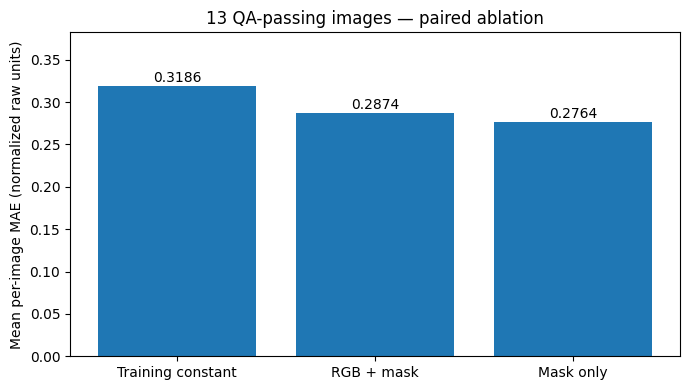

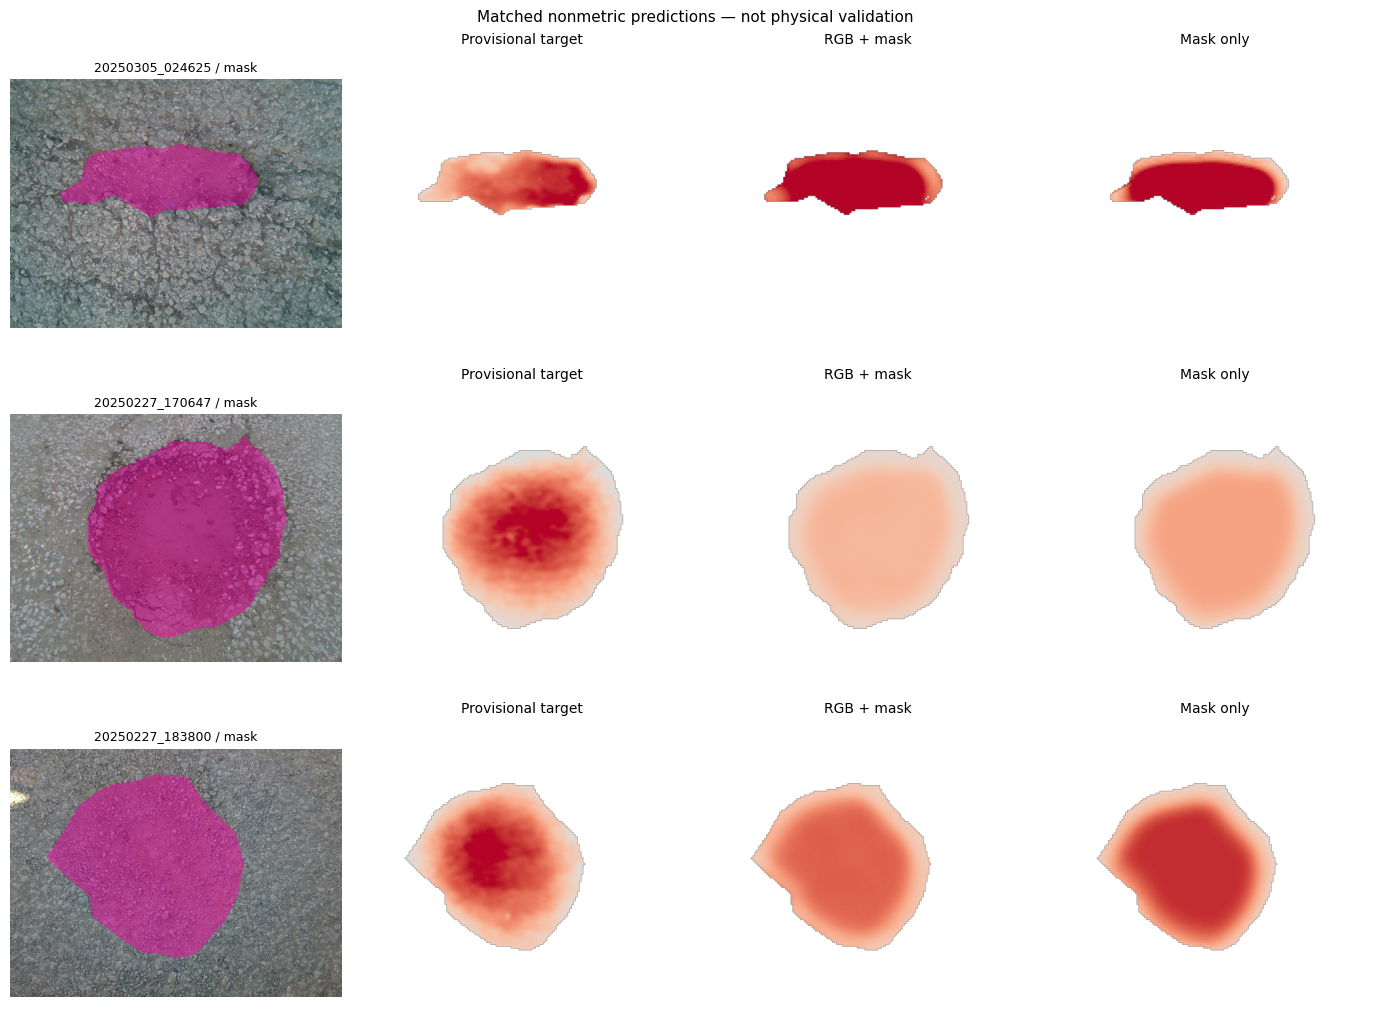


C3-03 SECTION 4B — PAIRED ABLATION COMPLETE
Compared QA-passing images: 13
RGB + mask mean MAE: 0.28736
Mask-only mean MAE: 0.27643
Training constant mean MAE: 0.31864
RGB wins: 7 | Mask-only wins: 6
Mask improvement over RGB (%): 3.8
Section 3 RGB score reproduction: PASS
Weights changed: NO
Independent metric validation: NO

Saved results: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-03_section04B_PAIRED_ABLATION_20261020T115539_608453Z


In [ ]:

# ============================================================
# C3-03 SECTION 4B — RGB vs MASK-ONLY PAIRED ABLATION
# Both trained checkpoints remain frozen.
# Uses only the 13 existing QA-passing evaluation frames.
# NO downloads, uploads, retraining, or metric-depth claims.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import hashlib, json, csv, importlib.util

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

RGBNAME = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)
MASKNAME = (
    "C3-03_section04_MASK_ONLY_ABLATION_"
    "20261020T101207_202510Z"
)
PROBENAME = (
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

RGBDIR = BASE / "06_model_checkpoints" / RGBNAME
MASKDIR = BASE / "06_model_checkpoints" / MASKNAME
MASKRUN = BASE / "05_training_runs" / MASKNAME
PROBEDIR = BASE / "07_evaluation" / PROBENAME

for d in (
    RGBDIR, MASKDIR, MASKRUN, PROBEDIR,
    DATA / "images", DATA / "labels", DATA / "depths"
):
    assert d.is_dir(), f"Missing directory: {d}"


# ------------------------------------------------------------
# 1. VERIFY SAVED RESEARCH SOURCES
# ------------------------------------------------------------

def digest(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def verify(folder, required):
    hashes = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        value, name = line.split(None, 1)
        name = name.strip()
        p = Path(name)

        assert not p.is_absolute()
        assert ".." not in p.parts

        hashes[name] = value

    for name in required:
        assert name in hashes
        assert digest(folder / name) == hashes[name], name

    return hashes


hrgb = verify(RGBDIR, [
    "crdl_dev_model.py",
    "model_development_only.pt"
])

hmask = verify(MASKDIR, [
    "crdl_dev_model.py",
    "mask_only_ablation.pt",
    "api_contract.json"
])

hmaskrun = verify(MASKRUN, [
    "training_config.json",
    "train_only_manifest.csv"
])

hprobe = verify(PROBEDIR, [
    "frozen_unseen_probe_report.json",
    "selected_unseen_samples.csv"
])

probe = json.loads(
    (PROBEDIR / "frozen_unseen_probe_report.json").read_text()
)

maskcfg = json.loads(
    (MASKRUN / "training_config.json").read_text()
)

assert probe["summary"]["attempted"] == 60
assert probe["summary"]["accepted_evaluation_count"] == 13

assert (
    probe["checkpoint_sha256"]
    == hrgb["model_development_only.pt"]
)

assert (
    maskcfg["original_rgb_checkpoint_sha256"]
    == hrgb["model_development_only.pt"]
)

assert (
    maskcfg["reserved_evaluation_manifest_sha256"]
    == hprobe["selected_unseen_samples.csv"]
)

assert maskcfg["section3_used_for_training"] is False
assert maskcfg["source_count"] == 33

assert (
    hrgb["crdl_dev_model.py"]
    == hmask["crdl_dev_model.py"]
)

accepted = [
    r for r in probe["records"]
    if r["status"] == "DIAGNOSTIC_PASS"
]

assert len(accepted) == 13

assert all(
    "model_mae_norm" in r
    and not r["model_trained_on_this_filename"]
    for r in accepted
)

with (
    PROBEDIR / "selected_unseen_samples.csv"
).open(newline="") as f:

    selection = {
        r["sample_id"]: r
        for r in csv.DictReader(f)
    }

with (
    MASKRUN / "train_only_manifest.csv"
).open(newline="") as f:

    training = {
        r["sample_id"]
        for r in csv.DictReader(f)
    }

assert len(selection) == 60
assert len(training) == 33
assert training.isdisjoint(selection)

assert {
    r["sample_id"] for r in accepted
}.issubset(selection)

print("Research integrity: PASS")
print("Reserved evaluation filenames:", len(selection))
print("QA-passing paired examples:", len(accepted))
print("Training/evaluation overlap: ZERO")


# ------------------------------------------------------------
# 2. LOAD BOTH FROZEN MODELS
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "c3_s04b_arch",
    RGBDIR / "crdl_dev_model.py"
)

arch = importlib.util.module_from_spec(spec)
spec.loader.exec_module(arch)

rgbpackage = torch.load(
    RGBDIR / "model_development_only.pt",
    map_location="cpu",
    weights_only=True
)

maskpackage = torch.load(
    MASKDIR / "mask_only_ablation.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    rgbpackage["contract_version"]
    == "C3_DEV_NONMETRIC_V1"
)

assert (
    maskpackage["contract_version"]
    == "C3_MASK_ONLY_ABLATION_V1"
)

assert maskpackage["rgb_channels_disabled"] is True
assert rgbpackage["metric_units_verified"] is False
assert maskpackage["metric_units_verified"] is False

SCALE = float(rgbpackage["raw_target_scale"])

assert np.isclose(
    SCALE,
    float(maskpackage["raw_target_scale"]),
    atol=1e-6
)

RGBMODEL = arch.CRDLDevUNet()
RGBMODEL.load_state_dict(
    rgbpackage["state_dict"],
    strict=True
)
RGBMODEL.eval()

MASKMODEL = arch.CRDLDevUNet()
MASKMODEL.load_state_dict(
    maskpackage["state_dict"],
    strict=True
)
MASKMODEL.eval()

CFG = probe["source_affine_config"]

CONSTANT = float(
    probe["summary"]["training_constant_value_norm"]
)

print("RGB model loaded: PASS")
print("Mask-only model loaded: PASS")
print("Original normalization:", round(SCALE, 4))


# ------------------------------------------------------------
# 3. REPRODUCE ORIGINAL POLYGON MASK PROCESSING
# ------------------------------------------------------------

def polygon_mask(path, w, h):
    canvas = Image.new("L", (w, h), 0)
    drawer = ImageDraw.Draw(canvas)

    count = 0

    for line in path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        vals = np.array(
            [float(x) for x in line.split()],
            dtype=np.float64
        )

        if (
            not np.isfinite(vals).all()
            or vals[0] != 0
            or len(vals) < 7
            or (len(vals) - 1) % 2
        ):
            raise ValueError("Invalid YOLO polygon")

        xy = vals[1:].reshape(-1, 2)

        if (
            (xy < -0.001).any()
            or (xy > 1.001).any()
        ):
            raise ValueError("Invalid polygon range")

        xy = np.clip(xy, 0, 1)

        drawer.polygon(
            [
                (
                    round(x * (w - 1)),
                    round(y * (h - 1))
                )
                for x, y in xy
            ],
            fill=1
        )

        count += 1

    result = np.asarray(canvas, dtype=bool)

    if count == 0 or not result.any():
        raise ValueError("Empty polygon")

    return result


# ------------------------------------------------------------
# 4. REPRODUCE THE LOCKED AFFINE REFERENCE METHOD
# ------------------------------------------------------------

def basis(xs, ys, w, h):
    return np.column_stack([
        (xs - (w-1)/2) / w,
        (ys - (h-1)/2) / h,
        np.ones(len(xs))
    ])


def irls(A, b):
    beta = np.linalg.lstsq(
        A, b, rcond=None
    )[0]

    for _ in range(CFG["irls_iterations"]):
        e = b - A @ beta
        med = np.median(e)

        mad = 1.4826 * np.median(
            np.abs(e-med)
        )

        cutoff = max(
            1.5 * mad, 1e-6
        )

        weights = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(e-med), 1e-12
                )
            )
        )

        new_beta = np.linalg.lstsq(
            A * weights[:, None],
            b * weights,
            rcond=None
        )[0]

        if np.max(
            np.abs(new_beta-beta)
        ) < 1e-9:
            beta = new_beta
            break

        beta = new_beta

    return beta


def reconstruct_reference(rgb, depth, mask, sid):
    h, w = depth.shape

    assert rgb.shape[:2] == (h, w)
    assert depth.dtype == np.uint16

    distance = distance_transform_edt(~mask)

    ring = (
        (depth > 0)
        & (distance >= CFG["ring_min_px"])
        & (distance <= CFG["ring_max_px"])
    )

    ry, rx = np.nonzero(ring)

    assert len(rx) >= CFG["min_support_pixels"]

    rng = np.random.default_rng(
        CFG["seed"] + int(sid[-6:])
    )

    chosen = rng.choice(
        len(rx),
        min(CFG["max_ring_samples"], len(rx)),
        replace=False
    )

    ry = ry[chosen]
    rx = rx[chosen]

    z = depth[ry, rx].astype(np.float64)

    low, high = np.quantile(
        z, [0.001, 0.999]
    )

    keep = (z >= low) & (z <= high)

    ry = ry[keep]
    rx = rx[keep]
    z = z[keep]

    A = basis(rx, ry, w, h)
    inv = 1000.0 / z

    beta = irls(A, inv)
    fit = A @ beta

    assert (fit > 0).all()

    road_p95 = float(
        np.percentile(
            np.abs(z - 1000.0/fit),
            95
        )
    )

    yy, xx = np.nonzero(
        mask & (depth > 0)
    )

    predicted_inv = (
        basis(xx, yy, w, h) @ beta
    )

    okay = predicted_inv > 0

    reference = np.full(
        len(predicted_inv),
        np.nan
    )

    reference[okay] = (
        1000.0 / predicted_inv[okay]
    )

    observed = depth[
        yy, xx
    ].astype(np.float64)

    plausible = (
        okay
        & (
            observed
            >= CFG["sensor_ratio_min"] * reference
        )
        & (
            observed
            <= CFG["sensor_ratio_max"] * reference
        )
    )

    residual = np.full(
        (h, w),
        np.nan,
        dtype=np.float32
    )

    residual[
        yy[plausible],
        xx[plausible]
    ] = (
        observed[plausible]
        - reference[plausible]
    ).astype(np.float32)

    return (
        residual,
        np.isfinite(residual),
        road_p95
    )


# ------------------------------------------------------------
# 5. MATCH ORIGINAL SUPERVISION PREPROCESSING
# ------------------------------------------------------------

def encode_supervision(rgb, mask, valid, target):
    x, g = arch.encode_input(
        rgb, mask,
        confidence=1.0,
        size=160
    )

    nh, nw = g["resized_hw"]
    top = g["pad_top"]
    left = g["pad_left"]

    vs = F.interpolate(
        torch.from_numpy(
            valid.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid, target, 0.0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    m = x[
        3,
        top:top+nh,
        left:left+nw
    ][None, None]

    weight = (
        (vs >= 0.90).float() * m
    )

    y = torch.where(
        weight > 0,
        (
            numerator
            / vs.clamp_min(1e-8)
        ) / SCALE,
        torch.zeros_like(numerator)
    )

    pad = (
        left, 160-nw-left,
        top, 160-nh-top
    )

    return (
        x,
        F.pad(y, pad).squeeze(0),
        F.pad(weight, pad).squeeze(0)
    )


# ------------------------------------------------------------
# 6. EVALUATE BOTH MODELS ON IDENTICAL IMAGES
# ------------------------------------------------------------

outrows = []
preview = []

with torch.no_grad():

    for k, old in enumerate(accepted, 1):

        sid = old["sample_id"]
        row = selection[sid]

        paths = {
            kind: DATA / folder / row[filename]
            for kind, folder, filename in [
                ("rgb", "images", "rgb_filename"),
                ("label", "labels", "label_filename"),
                ("depth", "depths", "depth_filename")
            ]
        }

        for path in paths.values():
            assert path.is_file()
            assert not path.is_symlink()

        for kind in ("rgb", "label", "depth"):
            assert (
                digest(paths[kind])
                == old[f"{kind}_sha256"]
            ), f"Modified source: {sid} {kind}"

        with Image.open(paths["rgb"]) as img:
            rgb = np.array(
                img.convert("RGB"),
                copy=True
            )

        depth = np.load(
            paths["depth"],
            allow_pickle=False
        )

        assert depth.dtype == np.uint16
        assert depth.ndim == 2
        assert depth.shape == rgb.shape[:2]

        mask = polygon_mask(
            paths["label"],
            depth.shape[1],
            depth.shape[0]
        )

        target, valid, road_p95 = (
            reconstruct_reference(
                rgb, depth, mask, sid
            )
        )

        # Verify the regenerated target reproduces
        # the original Section 3 evaluation evidence.
        assert np.isclose(
            road_p95,
            float(old["road_p95_raw"]),
            atol=0.0002
        ), f"Reference mismatch: {sid}"

        x, y, w = encode_supervision(
            rgb, mask, valid, target
        )

        assert w.sum().item() > 5

        xr = x.unsqueeze(0)

        xm = xr.clone()

        # The only model-input difference:
        # mask-only receives zero RGB channels.
        xm[:, :3, :, :] = 0.0

        pr = RGBMODEL(xr).squeeze(0)
        pm = MASKMODEL(xm).squeeze(0)

        idx = w > 0

        true = y[idx].numpy()
        pred_rgb = pr[idx].numpy()
        pred_mask = pm[idx].numpy()

        rgb_mae = float(
            np.mean(np.abs(true-pred_rgb))
        )

        mask_mae = float(
            np.mean(np.abs(true-pred_mask))
        )

        const_mae = float(
            np.mean(np.abs(true-CONSTANT))
        )

        zero_mae = float(
            np.mean(np.abs(true))
        )

        # Exact paired-evaluation integrity check.
        assert abs(
            rgb_mae - float(old["model_mae_norm"])
        ) < 2e-5, f"RGB reproduction failure: {sid}"

        assert abs(
            const_mae - float(old["constant_mae_norm"])
        ) < 2e-5

        assert abs(
            zero_mae - float(old["zero_mae_norm"])
        ) < 2e-5

        winner = (
            "RGB" if rgb_mae < mask_mae
            else "MASK" if mask_mae < rgb_mae
            else "TIE"
        )

        outrows.append({
            "sample_id": sid,
            "burst": old["burst"],
            "source_QA": "DIAGNOSTIC_PASS",
            "valid_resized_pixels": int(idx.sum()),
            "rgb_mae_norm": rgb_mae,
            "mask_only_mae_norm": mask_mae,
            "constant_mae_norm": const_mae,
            "zero_mae_norm": zero_mae,
            "rgb_minus_mask_mae": rgb_mae-mask_mae,
            "winner": winner
        })

        preview.append({
            "sid": sid,
            "rgb": rgb,
            "mask": mask,
            "target": y[0].numpy(),
            "rgb_pred": pr[0].numpy(),
            "mask_pred": pm[0].numpy(),
            "valid": w[0].numpy()
        })

        print(
            f"{k:02d}/13 | {sid} | "
            f"RGB: {rgb_mae:.4f} | "
            f"Mask-only: {mask_mae:.4f} | "
            f"Winner: {winner}"
        )


# ------------------------------------------------------------
# 7. COMPUTE PAIRED COMPARISON METRICS
# ------------------------------------------------------------

rgb_scores = np.array([
    r["rgb_mae_norm"] for r in outrows
])

mask_scores = np.array([
    r["mask_only_mae_norm"] for r in outrows
])

constant_scores = np.array([
    r["constant_mae_norm"] for r in outrows
])

difference = rgb_scores - mask_scores

assert len(outrows) == 13

assert abs(
    rgb_scores.mean()
    - probe["summary"]["mean_frozen_model_mae_norm"]
) < 2e-5

assert abs(
    constant_scores.mean()
    - probe["summary"]["mean_training_constant_mae_norm"]
) < 2e-5

# Descriptive bootstrap, NOT an independent-scene
# statistical confidence interval.
rng = np.random.default_rng(20261020)

indices = rng.integers(
    0,
    len(difference),
    size=(10000, len(difference))
)

interval = np.percentile(
    difference[indices].mean(axis=1),
    [2.5, 97.5]
).tolist()

summary = {
    "compared_frames": 13,
    "mean_rgb_mae_norm": float(rgb_scores.mean()),
    "mean_mask_only_mae_norm": float(mask_scores.mean()),
    "mean_train_constant_mae_norm":
        float(constant_scores.mean()),
    "mean_rgb_minus_mask_mae":
        float(difference.mean()),
    "mask_improvement_over_rgb_percent":
        float(
            100 * difference.mean()
            / rgb_scores.mean()
        ),
    "rgb_wins": int(
        (rgb_scores < mask_scores).sum()
    ),
    "mask_wins": int(
        (mask_scores < rgb_scores).sum()
    ),
    "ties": int(
        (rgb_scores == mask_scores).sum()
    ),
    "rgb_beats_constant": int(
        (rgb_scores < constant_scores).sum()
    ),
    "mask_beats_constant": int(
        (mask_scores < constant_scores).sum()
    ),
    "descriptive_frame_bootstrap_95pct_for_RGB_minus_MASK":
        interval,
    "units": "NORMALIZED_UNVERIFIED_RAW_SENSOR",
    "independent_physical_scene_validation": False
}


# ------------------------------------------------------------
# 8. CREATE VERSIONED REPORT DIRECTORY
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = (
    BASE / "07_evaluation"
    / f"C3-03_section04B_PAIRED_ABLATION_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

with (
    OUT / "paired_per_image.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(outrows[0])
    )

    writer.writeheader()
    writer.writerows(outrows)

report = {
    "milestone": "C3-03",
    "section": "4B",
    "version": "1.0",
    "rgb_checkpoint_sha256":
        hrgb["model_development_only.pt"],
    "mask_checkpoint_sha256":
        hmask["mask_only_ablation.pt"],
    "section3_report_sha256":
        hprobe["frozen_unseen_probe_report.json"],
    "same_13_previously_QA_accepted_frames": True,
    "new_training_performed": False,
    "reference_reconstructed_and_matched_to_section3": True,
    "reserved_evaluation_samples_used_for_training": False,
    "physical_units_verified": False,
    "severity_authorized": False,
    "interpretation": (
        "Paired exploratory comparison on 13 "
        "pseudo-label QA-passing images from the "
        "same collection. Not independent validation."
    ),
    "summary": summary,
    "per_image": outrows
}

(
    OUT / "paired_ablation_report.json"
).write_text(
    json.dumps(report, indent=2)
)


# ------------------------------------------------------------
# 9. COMPARE THE MEAN ERRORS VISUALLY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4))

values = [
    constant_scores.mean(),
    rgb_scores.mean(),
    mask_scores.mean()
]

ax.bar(
    [
        "Training constant",
        "RGB + mask",
        "Mask only"
    ],
    values
)

ax.set_ylabel(
    "Mean per-image MAE (normalized raw units)"
)

ax.set_title(
    "13 QA-passing images — paired ablation"
)

for i, v in enumerate(values):
    ax.text(
        i, v+0.005,
        f"{v:.4f}",
        ha="center"
    )

ax.set_ylim(0, max(values)*1.2)

fig.tight_layout()

fig.savefig(
    OUT / "paired_mean_mae.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. VISUALIZE BOTH PREDICTIONS SIDE BY SIDE
# ------------------------------------------------------------

# Select largest RGB advantage, largest mask
# advantage, and median paired difference.
chosen = [
    int(np.argmin(difference)),
    int(np.argmax(difference)),
    int(
        np.argsort(difference)[
            len(difference)//2
        ]
    )
]

chosen = list(dict.fromkeys(chosen))

fig, axes = plt.subplots(
    len(chosen),
    4,
    figsize=(14, 3.5*len(chosen)),
    squeeze=False
)

for i, j in enumerate(chosen):

    ex = preview[j]

    good = ex["valid"] > 0

    target = np.where(
        good, ex["target"], np.nan
    )

    pred_rgb = np.where(
        good, ex["rgb_pred"], np.nan
    )

    pred_mask = np.where(
        good, ex["mask_pred"], np.nan
    )

    color_scale = max(
        0.15,
        float(
            np.nanpercentile(
                np.abs(target), 95
            )
        )
    )

    overlay = ex["rgb"].copy()

    overlay[ex["mask"]] = (
        0.55 * overlay[ex["mask"]]
        + 0.45 * np.array([255, 0, 170])
    ).astype(np.uint8)

    axes[i, 0].imshow(overlay)

    axes[i, 0].set_title(
        ex["sid"] + " / mask",
        fontsize=9
    )

    for col, (arr, title) in enumerate([
        (target, "Provisional target"),
        (pred_rgb, "RGB + mask"),
        (pred_mask, "Mask only")
    ], 1):

        axes[i, col].imshow(
            np.ma.masked_invalid(arr),
            cmap="coolwarm",
            vmin=-color_scale,
            vmax=color_scale
        )

        axes[i, col].set_title(
            title,
            fontsize=10
        )

    for a in axes[i]:
        a.axis("off")

fig.suptitle(
    "Matched nonmetric predictions — "
    "not physical validation",
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    OUT / "paired_spatial_previews.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 11. SAVE CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{digest(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 12. FINAL RESEARCH SUMMARY
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-03 SECTION 4B — PAIRED ABLATION COMPLETE")
print("="*65)

print("Compared QA-passing images:", len(outrows))

print(
    "RGB + mask mean MAE:",
    round(summary["mean_rgb_mae_norm"], 5)
)

print(
    "Mask-only mean MAE:",
    round(summary["mean_mask_only_mae_norm"], 5)
)

print(
    "Training constant mean MAE:",
    round(summary["mean_train_constant_mae_norm"], 5)
)

print(
    "RGB wins:", summary["rgb_wins"],
    "| Mask-only wins:", summary["mask_wins"]
)

print(
    "Mask improvement over RGB (%):",
    round(
        summary["mask_improvement_over_rgb_percent"],
        2
    )
)

print("Section 3 RGB score reproduction: PASS")
print("Weights changed: NO")
print("Independent metric validation: NO")
print("\nSaved results:", OUT)

print("="*65)


Source report integrity: PASS
Existing diagnostic targets: 16
Independent capture groups verified: NO
Metric units verified: NO
All 16 target-file checks: PASS


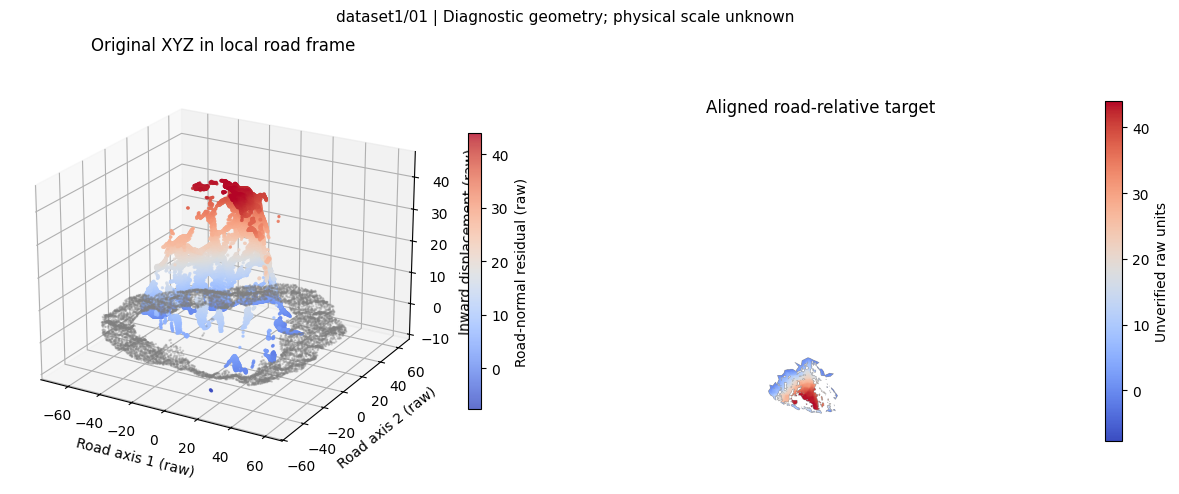

dataset1/01 | 3D target reconstruction PASS | Max difference: 0.00000191 raw units


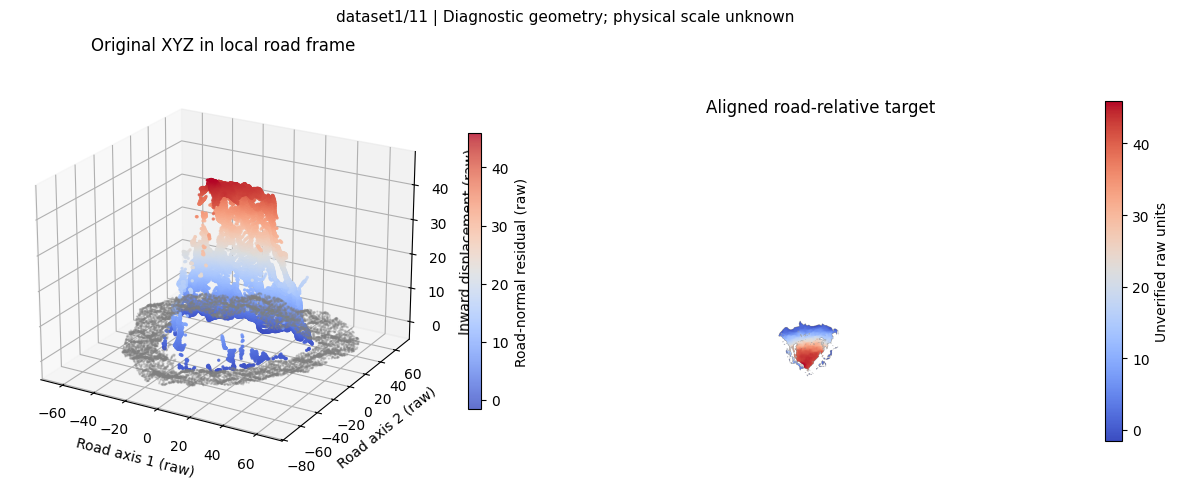

dataset1/11 | 3D target reconstruction PASS | Max difference: 0.00000191 raw units


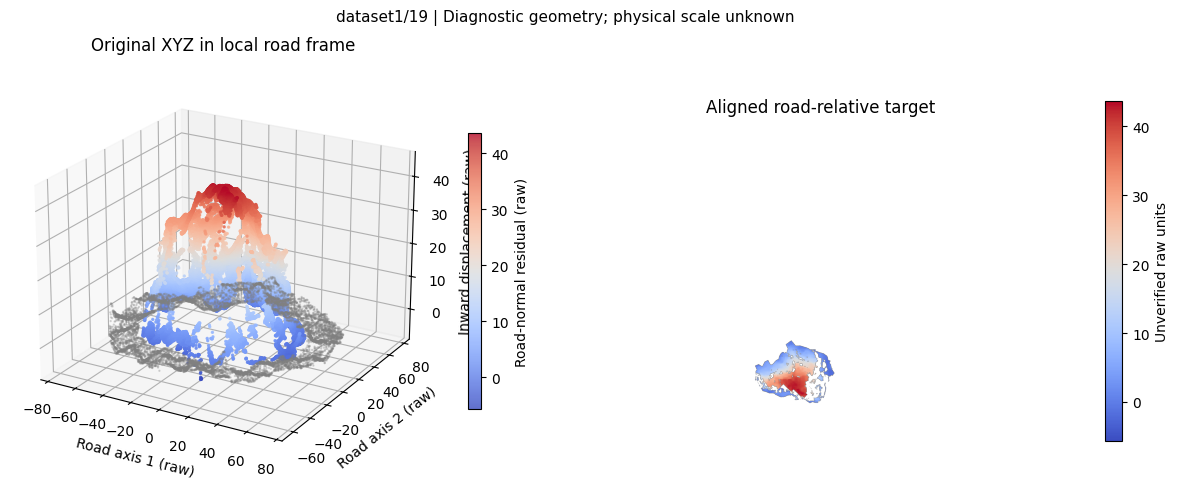

dataset1/19 | 3D target reconstruction PASS | Max difference: 0.00000191 raw units

C3-04 SECTION 1 — 3D ROAD GEOMETRY
Diagnostic NPZs verified: 16
Original XYZ point clouds checked: 3
Maximum reconstruction difference: 1.9073121819701555e-06
Conservative capture groups: 1
Physical depth units: UNVERIFIED
Independent validation: NOT PERFORMED
Model training: NOT PERFORMED

Saved output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-04_section01_FAN_3D_REFERENCE_20261020T120546_737207Z


In [ ]:

# ============================================================
# C3-04 SECTION 1 — FAN 3D ROAD-RELATIVE CONSISTENCY
#
# Reads original point clouds from Google Drive.
# Uses existing locked Fan diagnostic targets.
# Verifies original XYZ against saved road-normal targets.
#
# DATASET 1 ONLY.
# Dataset 2 and historical test sets stay protected.
# Physical units are NOT verified.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

from scipy.io import loadmat
from scipy.ndimage import distance_transform_edt

import matplotlib.pyplot as plt
import numpy as np
import hashlib
import json
import csv


# ------------------------------------------------------------
# 1. SOURCE PATHS
# ------------------------------------------------------------

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

FAN = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "fan_stereo_pothole/"
    "stereo_pothole_datasets-master/"
    "dataset1/ptcloud"
)

BATCH = BASE / (
    "04_geometry_targets/"
    "C3-02_section04_BATCH_20261020T064109_316286Z"
)

HANDOFF = BASE / (
    "04_geometry_targets/"
    "C3-02_section05_HANDOFF_20261020T065059_185606Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for folder in (FAN, BATCH, HANDOFF):
    assert folder.is_dir(), (
        f"Missing folder: {folder}"
    )


# ------------------------------------------------------------
# 2. VERIFY RESEARCH SOURCE INTEGRITY
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def verified(folder, required):

    refs = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, relative = line.split(None, 1)

        relative = relative.strip()
        p = Path(relative)

        assert not p.is_absolute()
        assert ".." not in p.parts

        refs[relative] = digest

    for relative in required:

        assert relative in refs

        path = folder / relative

        assert path.is_file()

        assert sha256(path) == refs[relative], (
            f"Checksum mismatch: {path}"
        )

    return refs


hb = verified(
    BATCH,
    ["fan_batch_diagnostic_report.json"]
)

hh = verified(
    HANDOFF,
    [
        "diagnostic_handoff_report.json",
        "provisional_target_contract.json",
        "diagnostic_target_manifest.csv"
    ]
)

batch = json.loads(
    (
        BATCH / "fan_batch_diagnostic_report.json"
    ).read_text()
)

handoff = json.loads(
    (
        HANDOFF / "diagnostic_handoff_report.json"
    ).read_text()
)

contract = json.loads(
    (
        HANDOFF / "provisional_target_contract.json"
    ).read_text()
)

assert (
    handoff["source_batch_report_sha256"]
    == hb["fan_batch_diagnostic_report.json"]
)

assert handoff["verified_npz_count"] == 16

assert (
    handoff["source_group_count_for_model_validation"]
    == 1
)

assert not handoff["metric_depth_units_verified"]
assert not handoff["training_split_assigned"]
assert not batch["dataset2_read"]
assert not batch["dataset3_read"]
assert not batch["metric_units_verified"]

assert (
    contract["reference_target"]["key"]
    == "inward_signed_raw"
)

passes = sorted(
    [
        r for r in batch["results"]
        if r["status"] == "DIAGNOSTIC_PASS"
    ],
    key=lambda r: r["sample_id"]
)

assert len(passes) == 16

assert len({
    r["physical_group"]
    for r in passes
}) == 1

print("Source report integrity: PASS")
print("Existing diagnostic targets:", len(passes))
print("Independent capture groups verified: NO")
print("Metric units verified: NO")


# ------------------------------------------------------------
# 3. CREATE NEW VERSIONED OUTPUT FOLDER
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "04_geometry_targets" / (
    "C3-04_section01_FAN_3D_REFERENCE_" + stamp
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)


# ------------------------------------------------------------
# 4. VERIFY ALL EXISTING ROAD-RELATIVE TARGETS
# ------------------------------------------------------------

rows = []

for rec in passes:

    relative = rec["npz"]

    assert relative.startswith(
        "diagnostic_pass_npz/"
    )

    hashes = verified(
        BATCH,
        [relative]
    )

    with np.load(
        BATCH / relative,
        allow_pickle=False
    ) as p:

        z = p["inward_signed_raw"]

        mask = p[
            "damage_mask"
        ].astype(bool)

        valid = p[
            "valid_target_mask"
        ].astype(bool)

        xyzvalid = p[
            "valid_xyz_mask"
        ].astype(bool)

        normal = p[
            "normal_toward_camera_raw"
        ]

        reference = p[
            "reference_point_raw"
        ]

        assert z.dtype == np.float32

        assert (
            z.shape == mask.shape
            == valid.shape == xyzvalid.shape
        )

        assert np.array_equal(
            np.isfinite(z),
            valid
        )

        assert np.all(
            ~valid | mask
        )

        assert normal.shape == (3,)
        assert reference.shape == (3,)

        assert np.isfinite(normal).all()
        assert np.isfinite(reference).all()

        assert abs(
            np.linalg.norm(normal)-1
        ) < 1e-6

        values = z[valid]

        assert len(values) > 100

        coverage = float(
            valid.sum() / mask.sum()
        )

        assert np.isclose(
            coverage,
            rec["coverage"],
            atol=1e-6
        )

        rows.append({
            "sample_id": rec["sample_id"],
            "capture_group": rec["physical_group"],
            "valid_pixels": int(valid.sum()),
            "damage_pixels": int(mask.sum()),
            "damage_coverage": coverage,
            "median_inward_raw": float(
                np.median(values)
            ),
            "mean_inward_raw": float(
                np.mean(values)
            ),
            "d95_inward_raw": float(
                np.percentile(values, 95)
            ),
            "positive_fraction": float(
                np.mean(values > 0)
            ),
            "road_abs_p95_raw": float(
                rec["road_abs_p95_raw"]
            ),
            "holdout_to_signal": float(
                rec["heldout_ratio"]
            ),
            "source_npz_sha256": hashes[relative],
            "physical_units_verified": False
        })

print("All 16 target-file checks: PASS")


# ------------------------------------------------------------
# 5. SELECT REPRESENTATIVE ORIGINAL POINT CLOUDS
# ------------------------------------------------------------

# All available frames belong to one conservative
# capture group. These are NOT independent tests.

chosen = [
    passes[0],
    passes[len(passes)//2],
    passes[-1]
]

selected_report = []


# ------------------------------------------------------------
# 6. RECONSTRUCT THE LOCAL ROAD COORDINATE SYSTEM
# ------------------------------------------------------------

for rec in chosen:

    sid = rec["sample_id"]
    number = sid.split("/")[-1]

    xyz_file = FAN / (number + ".mat")

    assert xyz_file.is_file()
    assert not xyz_file.is_symlink()

    assert sha256(xyz_file) == (
        rec["source_xyz_sha256"]
    ), f"Point cloud changed: {sid}"

    with np.load(
        BATCH / rec["npz"],
        allow_pickle=False
    ) as p:

        target = p[
            "inward_signed_raw"
        ].copy()

        mask = p[
            "damage_mask"
        ].astype(bool)

        valid = p[
            "valid_target_mask"
        ].astype(bool)

        xyzvalid = p[
            "valid_xyz_mask"
        ].astype(bool)

        normal = p[
            "normal_toward_camera_raw"
        ].copy()

        p0 = p[
            "reference_point_raw"
        ].copy()

    # Original 3D coordinates, not estimated
    # from RGB and not a pseudo-point-cloud.
    mat = loadmat(
        xyz_file,
        variable_names=["xyzPoints"]
    )

    assert "xyzPoints" in mat

    xyz = mat["xyzPoints"]

    assert xyz.dtype.kind == "f"

    assert xyz.shape == (
        *mask.shape, 3
    )

    # Sample valid points within the pothole.
    rng = np.random.default_rng(
        20261020 + int(number)
    )

    yy, xx = np.nonzero(
        valid & xyzvalid
    )

    assert len(xx) > 300

    ids = rng.choice(
        len(xx),
        size=min(25000, len(xx)),
        replace=False
    )

    points = xyz[
        yy[ids],
        xx[ids],
        :
    ]

    # Recompute inward displacement along
    # the stored local road normal.
    recomputed = -(
        (points-p0) @ normal
    )

    stored = target[
        yy[ids],
        xx[ids]
    ].astype(np.float64)

    max_error = float(
        np.max(
            np.abs(recomputed-stored)
        )
    )

    assert max_error < 1e-3, (
        f"3D target inconsistency: "
        f"{sid}: {max_error}"
    )

    # Construct two axes lying in the road plane.
    initial = np.array([
        1.0, 0.0, 0.0
    ])

    e1 = (
        initial
        - normal * np.dot(initial, normal)
    )

    if np.linalg.norm(e1) < 0.01:

        initial = np.array([
            0.0, 1.0, 0.0
        ])

        e1 = (
            initial
            - normal * np.dot(initial, normal)
        )

    e1 /= np.linalg.norm(e1)

    e2 = np.cross(
        normal, e1
    )

    e2 /= np.linalg.norm(e2)

    def road_coords(pts):

        relative = pts-p0

        return (
            relative @ e1,
            relative @ e2,
            -(relative @ normal)
        )

    hole_x, hole_y, hole_d = (
        road_coords(points)
    )

    # Sample intact road around the pothole.
    distance = distance_transform_edt(
        ~mask
    )

    healthy_ring = (
        (~mask)
        & xyzvalid
        & np.isfinite(xyz).all(axis=2)
        & (distance >= 8)
        & (distance <= 55)
    )

    hy, hx = np.nonzero(
        healthy_ring
    )

    assert len(hx) > 1000

    healthy_ids = rng.choice(
        len(hx),
        size=min(9000, len(hx)),
        replace=False
    )

    healthy_points = xyz[
        hy[healthy_ids],
        hx[healthy_ids],
        :
    ]

    road_x, road_y, road_d = (
        road_coords(healthy_points)
    )

    # --------------------------------------------------------
    # 7. VISUALIZE REAL 3D GEOMETRY AND SAVED TARGET
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(13, 5)
    )

    ax = fig.add_subplot(
        121,
        projection="3d"
    )

    ax.scatter(
        road_x,
        road_y,
        road_d,
        s=0.5,
        c="gray",
        alpha=0.28,
        rasterized=True
    )

    scatter = ax.scatter(
        hole_x,
        hole_y,
        hole_d,
        s=2,
        c=hole_d,
        cmap="coolwarm",
        alpha=0.8,
        rasterized=True
    )

    ax.set_xlabel(
        "Road axis 1 (raw)"
    )

    ax.set_ylabel(
        "Road axis 2 (raw)"
    )

    ax.set_zlabel(
        "Inward displacement (raw)"
    )

    ax.set_title(
        "Original XYZ in local road frame"
    )

    ax.view_init(
        elev=22,
        azim=-60
    )

    fig.colorbar(
        scatter,
        ax=ax,
        shrink=0.65,
        label="Road-normal residual (raw)"
    )

    bx = fig.add_subplot(
        122
    )

    display = np.where(
        valid,
        target,
        np.nan
    )

    im = bx.imshow(
        np.ma.masked_invalid(display),
        cmap="coolwarm"
    )

    bx.set_title(
        "Aligned road-relative target"
    )

    bx.axis("off")

    fig.colorbar(
        im,
        ax=bx,
        shrink=0.8,
        label="Unverified raw units"
    )

    fig.suptitle(
        sid
        + " | Diagnostic geometry; physical scale unknown",
        fontsize=11
    )

    fig.tight_layout()

    figure_path = (
        OUT / f"fan_{number}_road_frame_3d.png"
    )

    fig.savefig(
        figure_path,
        dpi=130,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(
        f"{sid} | 3D target reconstruction PASS "
        f"| Max difference: {max_error:.8f} raw units"
    )

    selected_report.append({
        "sample_id": sid,
        "source_xyz_sha256":
            rec["source_xyz_sha256"],
        "residual_reconstruction_max_abs_error_raw":
            max_error,
        "healthy_support_points_plotted":
            int(len(healthy_points)),
        "pothole_points_plotted":
            int(len(points)),
        "figure": figure_path.name
    })

    del xyz, mat


# ------------------------------------------------------------
# 8. SAVE GEOMETRY PROFILES
# ------------------------------------------------------------

with (
    OUT / "geometry_profiles_nonmetric.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(rows[0])
    )

    writer.writeheader()
    writer.writerows(rows)


report = {
    "stage": "C3-04_section01",
    "source_dataset": "FAN_dataset1_only",
    "previous_report_sha256":
        hb["fan_batch_diagnostic_report.json"],
    "source_capture_groups": 1,
    "diagnostic_frames": len(rows),
    "real_xyz_pointclouds_reopened":
        len(chosen),
    "metric_scale_verified": False,
    "road_normal_orientation_independently_verified":
        False,
    "physical_scene_independence_verified":
        False,
    "severity_thresholds_in_mm_authorized":
        False,
    "model_training_performed": False,
    "conclusion": (
        "3D coordinate consistency engineering check. "
        "Physical depth units and independent "
        "generalization are not established."
    ),
    "samples_3d": selected_report
}

(
    OUT / "pointcloud_feasibility_report.json"
).write_text(
    json.dumps(report, indent=2)
)


# ------------------------------------------------------------
# 9. SAVE CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{sha256(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 10. FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-04 SECTION 1 — 3D ROAD GEOMETRY")
print("="*65)

print(
    "Diagnostic NPZs verified:",
    len(rows)
)

print(
    "Original XYZ point clouds checked:",
    len(selected_report)
)

print(
    "Maximum reconstruction difference:",
    max(
        r["residual_reconstruction_max_abs_error_raw"]
        for r in selected_report
    )
)

print("Conservative capture groups: 1")
print("Physical depth units: UNVERIFIED")
print("Independent validation: NOT PERFORMED")
print("Model training: NOT PERFORMED")

print("\nSaved output:", OUT)
print("="*65)
